# 06 — Composability: a pretrained module inside a new compound architecture

**Question.** Every transfer so far reused a network in its original shape:
same encoder, same single-image input, new head. But the deeper promise of
feature reuse is *modularity* — a trained encoder should work as a
**component** inside an architecture it was never trained for. The test:
given **two** digit images, predict only their **sum** (19 classes). The
supervision is weak/distant — no per-digit label is ever shown, only a
function of the two hidden identities.

**What the literature says.**
- Yosinski et al. (NeurIPS 2014): pretrained features are reusable objects
  in their own right; nothing ties them to the head — or the architecture —
  they were trained under. Feature reuse is the mechanism.
- Andreas et al., *Neural Module Networks* (CVPR 2016): assemble a
  task-specific architecture from reusable neural modules. Composition,
  not just fine-tuning, is a transfer mechanism.
- Two-digit MNIST addition is the standard benchmark for learning under
  distant supervision (Manhaeve et al., *DeepProbLog*, NeurIPS 2018): the
  sum constrains the digit identities only jointly, never individually.

**The compound architecture.** `PairSumNet` runs a twin (weight-shared)
encoder over both images and feeds the concatenated embeddings to a small
MLP combiner (2×128 → 128 → 19, ~35k params). We drop the notebook-00 MNIST
source encoder (trained on single digits with a 10-way head) into that
slot — frozen or fine-tunable — and compare against a randomly initialized
encoder trained end-to-end from the sum labels alone.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tllab").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
import torch

import tllab
from tllab import analysis, data, models, train

tllab.setup()

src = train.train_or_load_source("mnist")
tllab.set_seed(0)
_net = models.PairSumNet(None)
print(f"PairSumNet: {models.param_count(_net):,} params total, "
      f"{models.param_count(_net.combiner):,} in the combiner")

tllab: torch 2.13.0+cu130 | threads=4 | QUICK=False | root=/home/user/transfer-learning-lab
[ckpt cached] mnist: test_acc=0.985
PairSumNet: 231,539 params total, 35,347 in the combiner


## The task and its trivial baselines

The sum of two uniform digits has a **triangular** label distribution:
sum=9 is about 10× likelier than 0 or 18. Plain accuracy is therefore kind
to a mode-guesser — always answering 9 already scores ~10% — so we track
**MAE** as well (always-9 costs ≈3.3), which exposes whether a model has
learned any magnitude information and treats near misses fairly on an
ordinal label.

Final metrics are always computed on one fixed test set of 4,000 pairs.
(Per-epoch tracking inside `fit_pair` runs on a separate 1,000-pair subset
purely to keep the 30-epoch runs cheap; it is not used in any figure.)

In [2]:
pair_test = data.make_pair_sum(tllab.q(4000, 500), seed=0, split="test")
track_test = data.make_pair_sum(tllab.q(1000, 200), seed=1, split="test")

counts = torch.bincount(pair_test.y, minlength=19)
mode_class = int(counts.argmax())
maj_acc = counts.max().item() / len(pair_test.y)
mode_mae = float((pair_test.y - mode_class).abs().float().mean())
print(pair_test)
print(f"label mode: sum={mode_class} -> majority accuracy {maj_acc:.3f}, "
      f"always-{mode_class} MAE {mode_mae:.2f}")

PairTask('pairsum-test', 19 classes, n=4000)
label mode: sum=9 -> majority accuracy 0.101, always-9 MAE 3.37


## The experiment

Three encoder conditions at n ∈ {500, 2000, 8000} training pairs
(3 seeds for n ≤ 2000; batch 64 at the smallest n for convergence,
128 otherwise):

| condition | encoder init | encoder trained? | combiner |
|---|---|---|---|
| frozen | pretrained MNIST encoder (frozen) | no | trained |
| fine-tune | pretrained MNIST encoder | yes | trained |
| scratch | random | yes | trained |

All three use a **single learning rate (1e-3) for symmetry** — deliberately
*without* notebook 01's 10× fine-tuning discount. That choice has a known
cost: at tiny n, gradients from the randomly initialized combiner can
transiently damage the pretrained features before the combiner settles
(the same mechanism notebook 04 dissected). Freezing protects them — watch
the n=500 column for exactly that.

In [3]:
N_GRID = [500, 2000, 8000]
EPOCHS = {500: 30, 2000: 15, 8000: 8}
BATCH = {500: 64, 2000: 128, 8000: 128}
CONDITIONS = ["frozen", "fine-tune", "scratch"]


def build_net(condition: str, seed: int) -> models.PairSumNet:
    tllab.set_seed(seed)
    if condition == "scratch":
        return models.PairSumNet(None)
    net = models.PairSumNet(models.clone_encoder(src))  # src never mutated
    if condition == "frozen":
        models.freeze_encoder(net)
    return net


def composition_sweep() -> pd.DataFrame:
    rows = []
    for n in N_GRID:
        n_run = tllab.q(n, n // 10)
        epochs = tllab.q(EPOCHS[n], max(2, EPOCHS[n] // 10))
        for seed in (tllab.seeds() if n <= 2000 else [0]):
            pairs = data.make_pair_sum(n_run, seed, "train")
            for cond in CONDITIONS:
                net = build_net(cond, seed)
                res = train.fit_pair(net, pairs, track_test, epochs=epochs,
                                     batch_size=BATCH[n], seed=seed)
                acc, mae = train.evaluate_pair(net, pair_test)
                rows.append({"condition": cond, "n_pairs": n_run,
                             "seed": seed, "acc": acc, "mae": mae,
                             "wall_s": round(res.wall_s, 1)})
                print(f"  n={n_run} seed={seed} {cond:>9s}: acc={acc:.3f} "
                      f"mae={mae:.2f} ({res.wall_s:.0f}s)")
    return pd.DataFrame(rows)


df = train.cached_sweep("06_composition", composition_sweep)
df.pivot_table(index="n_pairs", columns="condition", values=["acc", "mae"])

[sweep cached] 06_composition.csv


acc                           mae                    
condition fine-tune    frozen   scratch fine-tune    frozen   scratch
n_pairs                                                              
500         0.63075  0.722333  0.286333  1.054833  0.839667  2.093583
2000        0.88400  0.892167  0.528500  0.399583  0.359000  1.227750
8000        0.93425  0.931750  0.906250  0.260750  0.231750  0.321500

figure -> artifacts/figures/06_composition_vs_n.png


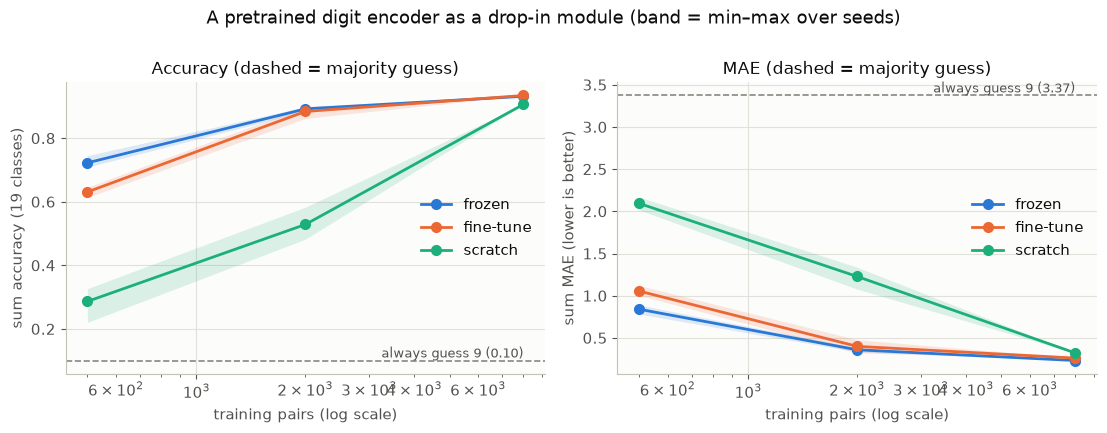

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.3), sharex=True)
x_hi = df["n_pairs"].max()

analysis.plot_curves(df, x="n_pairs", y="acc", hue="condition", ax=axes[0],
                     logx=True, ylabel="sum accuracy (19 classes)",
                     title="Accuracy (dashed = majority guess)")
axes[0].axhline(maj_acc, color="#898781", linestyle="--", linewidth=1.2)
axes[0].annotate(f"always guess {mode_class} ({maj_acc:.2f})",
                 (x_hi, maj_acc), ha="right", va="bottom",
                 fontsize=9, color="#52514e")

analysis.plot_curves(df, x="n_pairs", y="mae", hue="condition", ax=axes[1],
                     logx=True, ylabel="sum MAE (lower is better)",
                     title="MAE (dashed = majority guess)")
axes[1].axhline(mode_mae, color="#898781", linestyle="--", linewidth=1.2)
axes[1].annotate(f"always guess {mode_class} ({mode_mae:.2f})",
                 (x_hi, mode_mae), ha="right", va="bottom",
                 fontsize=9, color="#52514e")

for ax in axes:
    ax.set_xlabel("training pairs (log scale)")
fig.suptitle("A pretrained digit encoder as a drop-in module "
             "(band = min–max over seeds)", y=1.0)
analysis.savefig("06_composition_vs_n")

## Takeaways

- **A frozen pretrained module makes the compound task learnable at 500
  pairs.** The combiner only has to learn arithmetic on top of digit-aware
  features — a 35k-parameter head problem — while end-to-end scratch must
  *invent digit recognition from sum supervision alone* and barely beats
  the majority guesser at that size. The encoder was trained on single
  images with a 10-way head; it had never seen a pair, a sum, or the
  combiner it now feeds — yet it plugs straight in. That is Yosinski-style
  feature reuse expressed as Andreas-style composition.
- **Weak supervision is expensive, and data pays the bill.** By 8000 pairs
  scratch closes much of the gap — the notebook-01 story again, now for a
  compound architecture: pretraining mostly moves the learning curve left
  (sample efficiency), it does not raise the ceiling.
- **Fine-tuning at a single shared LR is a gamble at tiny n.** With no
  LR discount, the random combiner's early gradients can transiently
  corrupt the pretrained encoder at n=500 (freezing is the protection);
  with enough pairs the extra plasticity should let fine-tuning catch or
  pass frozen. At MNIST scale that crossover is real but small and
  seed-dependent — hence a soft claim, not a hard one.
- **Why the MAE panel matters.** The triangular label distribution means
  accuracy alone flatters mode-guessers. MAE separates "predicts 9 every
  time" from "roughly knows the magnitude" — scratch at 500 pairs sits
  near the majority line on both panels, while the frozen module's errors
  are small *and* near-miss shaped.

**References.** Yosinski, Clune, Bengio & Lipson, *How transferable are
features in deep neural networks?* (NeurIPS 2014). Andreas, Rohrbach,
Darrell & Klein, *Neural Module Networks* (CVPR 2016). Manhaeve et al.,
*DeepProbLog: Neural Probabilistic Logic Programming* (NeurIPS 2018).
He, Girshick & Dollár, *Rethinking ImageNet Pre-training* (ICCV 2019).

In [5]:
if not tllab.config.QUICK:
    g = df.groupby(["condition", "n_pairs"])["acc"].mean()
    fr500, sc500 = g["frozen"][500], g["scratch"][500]
    sc8k = g["scratch"][8000]
    fr8k, ft8k = g["frozen"][8000], g["fine-tune"][8000]
    analysis.claim("frozen module beats scratch at 500 pairs by >10 pts",
                   fr500 > sc500 + 0.10, f"{fr500:.3f} vs {sc500:.3f}",
                   hard=True)
    analysis.claim("scratch improves >15 pts from 500 to 8000 pairs",
                   sc8k > sc500 + 0.15, f"{sc8k:.3f} vs {sc500:.3f}")
    analysis.claim("fine-tune catches frozen by 8000 pairs",
                   ft8k >= fr8k, f"{ft8k:.3f} vs {fr8k:.3f}")

CLAIM CHECK [PASS] frozen module beats scratch at 500 pairs by >10 pts — 0.722 vs 0.286
CLAIM CHECK [PASS] scratch improves >15 pts from 500 to 8000 pairs — 0.906 vs 0.286
CLAIM CHECK [PASS] fine-tune catches frozen by 8000 pairs — 0.934 vs 0.932
